# EDA – Bivariate and multivariate analysis

How does household energy use relate to other variables: electricity vs gas across household groups, PV, heating fuel, weekday vs weekend, outdoor temperature and solar irradiance? SERL 2020–2023.

**Inputs:** the daily-statistics file and the half-hourly files, read with `serl_utils`.
**Outputs:** figures inline; `outputs/repro/temperature_response_2023.csv`.

The earlier version of this notebook imputed medians and clipped every numeric column across the pooled table, and its PV flag searched for the text "pv" in values that are "Yes"/"No", so every household was classed as non-PV. Its interactive dashboard was built on the same pooled data and is not carried over.


Every number below comes from **one group of households in one unit**: SERL rows stack overlapping groups (whole sample, heating fuel, PV, region, EPC, …) and three units per quantity, and `serl_utils` refuses to mix them. The earlier version of this notebook averaged across all rows, e.g. reporting an "energy mean" of 206 that combined gas in Wh with electricity per m², and reading the resulting skewness as "extreme demand events".


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serl_utils as su

warnings.filterwarnings("ignore", category=UserWarning)
yearly = su.load_yearly()
monthly = su.load_monthly(su.CLEAN_CSV)
hh = su.load_half_hourly([2023])
y23 = yearly[yearly["year"].eq(2023)]
Path("outputs/repro").mkdir(parents=True, exist_ok=True)
TICKS = (range(0, 48, 4), [f"{h:02d}:00" for h in range(0, 24, 2)])

def kwh_day(df, q, **f):
    return su.select_slice(df, q, "kWh/day", **f)["mean"].iloc[0]

## 1. Electricity vs gas across household groups (2023)

Each point is one SERL household group (PV, heating fuel, and every level of every characteristic except temperature band). Groups that use more gas also tend to use more electricity, because both scale with home and household size; electric-heated homes are the exception.


72 groups; Spearman correlation electricity vs gas = 0.66 (p = 3.12e-10)


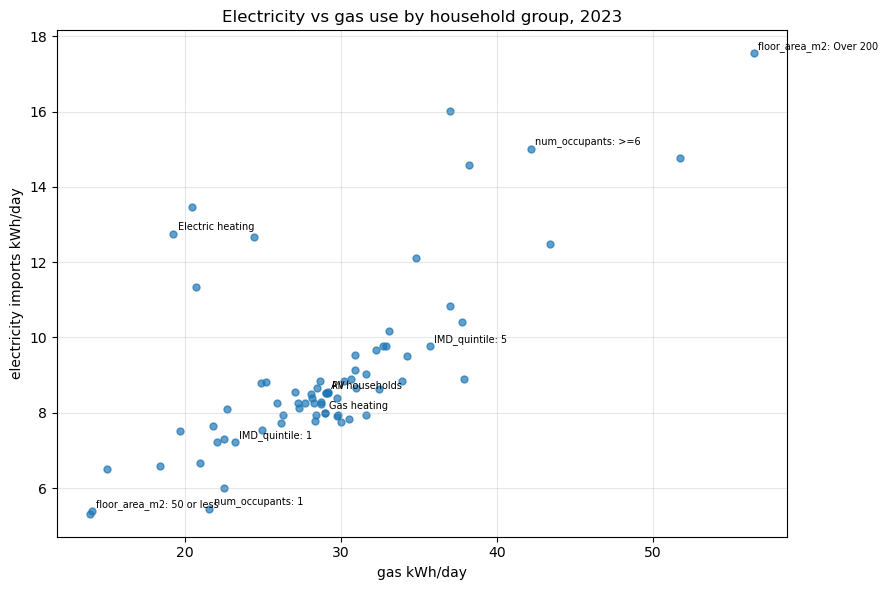

In [2]:
from scipy.stats import spearmanr

groups = [("All households", {}), ("PV", {"pv": "Yes"}), ("No PV", {"pv": "No"}),
          ("Gas heating", {"fuel": "Gas"}), ("Electric heating", {"fuel": "Electric"})]
for seg in sorted(y23["segmentation_variable_3"].dropna().unique()):
    if seg == "temperature_band":
        continue
    for lv in sorted(y23.loc[y23["segmentation_variable_3"].eq(seg), "segment_3_value"].dropna().astype(str).unique()):
        if lv != "All":
            groups.append((f"{seg}: {lv}", {"segment": seg, "segment_value": lv}))
rows = []
for name, f in groups:
    try:
        rows.append({"group": name, "electricity": kwh_day(y23, "Electricity imports", **f), "gas": kwh_day(y23, "Gas", **f)})
    except ValueError:
        pass                      # group not reported for this quantity
eg = pd.DataFrame(rows).dropna()
rho, p = spearmanr(eg["electricity"], eg["gas"])
print(f"{len(eg)} groups; Spearman correlation electricity vs gas = {rho:.2f} (p = {p:.3g})")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(eg["gas"], eg["electricity"], s=25, alpha=0.7)
for _, r in eg.iterrows():
    if r["group"].startswith(("All households", "PV", "Electric heating", "Gas heating", "floor_area_m2: Over", "floor_area_m2: 50",
                              "num_occupants: 1", "num_occupants: >=6", "IMD_quintile: 1", "IMD_quintile: 5")):
        ax.annotate(r["group"], (r["gas"], r["electricity"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("gas kWh/day"); ax.set_ylabel("electricity imports kWh/day")
ax.set_title("Electricity vs gas use by household group, 2023"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. PV vs non-PV homes (2023)

Half-hourly imports, exports and net use for households with and without solar PV.


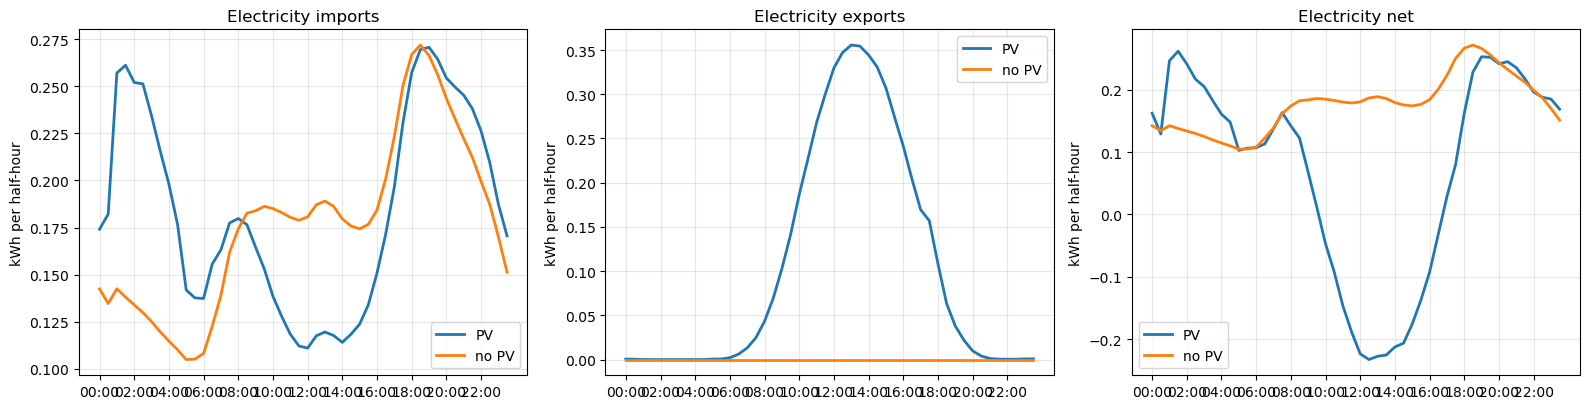

group                  PV  no PV
quantity                        
Electricity exports  5.05   0.00
Electricity imports  8.83   8.47
Electricity net      3.47   8.47


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
rows = []
for ax, q in zip(axes, ["Electricity imports", "Electricity exports", "Electricity net"]):
    for pv, label in (("Yes", "PV"), ("No", "no PV")):
        p = su.daily_profile(hh, 2023, q, "Wh", to_kwh=True, pv=pv)
        ax.plot(range(48), p.to_numpy(), label=label, linewidth=2)
        rows.append({"quantity": q, "group": label, "kWh/day": p.sum()})
    ax.set_xticks(*TICKS); ax.set_title(q); ax.set_ylabel("kWh per half-hour"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).pivot(index="quantity", columns="group", values="kWh/day").round(2).to_string())

## 3. Gas-heated vs electric-heated homes

Electricity imports through the day (2023) and through the year (monthly, 2020–2023).


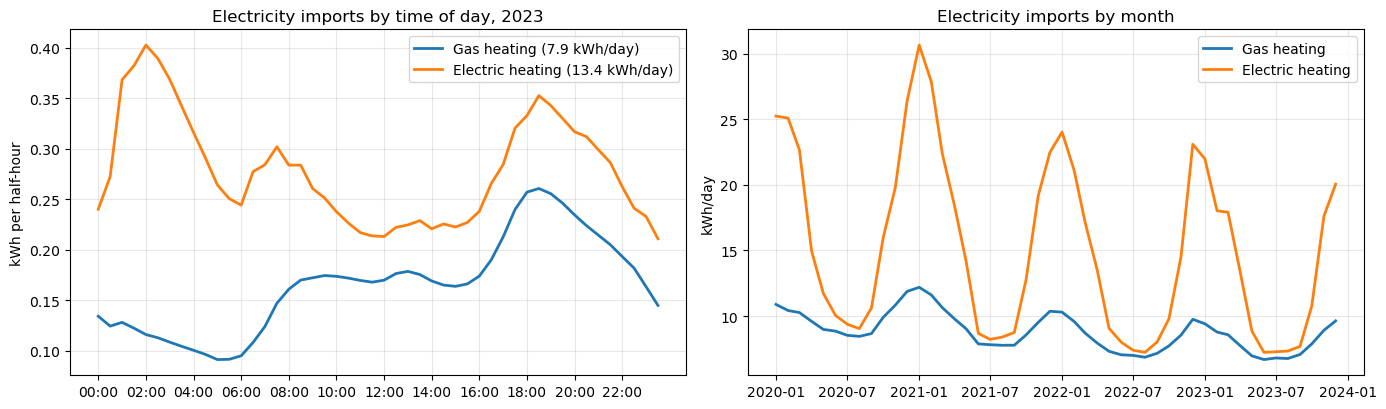

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for fuel in ("Gas", "Electric"):
    p = su.daily_profile(hh, 2023, "Electricity imports", "Wh", to_kwh=True, fuel=fuel)
    axes[0].plot(range(48), p.to_numpy(), label=f"{fuel} heating ({p.sum():.1f} kWh/day)", linewidth=2)
    s = su.monthly_series(monthly, "Electricity imports", "kWh/day", fuel=fuel)
    axes[1].plot(s.index, s.to_numpy(), label=f"{fuel} heating", linewidth=2)
axes[0].set_xticks(*TICKS); axes[0].set_title("Electricity imports by time of day, 2023")
axes[0].set_ylabel("kWh per half-hour")
axes[1].set_title("Electricity imports by month"); axes[1].set_ylabel("kWh/day")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Weekdays vs weekends

SERL splits weekdays and weekends for the whole sample only.


day type                  weekday  weekend  weekend / weekday
quantity            year                                     
Electricity imports 2020   10.799   11.435              1.059
                    2021    9.965   10.472              1.051
                    2022    8.670    9.043              1.043
                    2023    8.401    8.790              1.046
Gas                 2020   37.034   36.287              0.980
                    2021   38.103   40.128              1.053
                    2022   30.332   30.688              1.012
                    2023   28.980   29.274              1.010


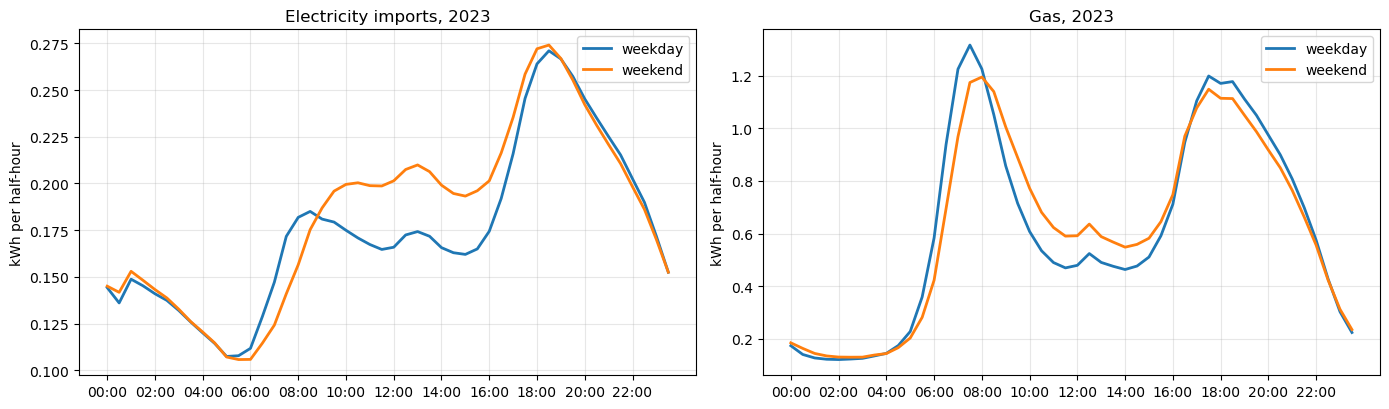

In [5]:
rows = []
for q in ["Electricity imports", "Gas"]:
    for day in ("weekday", "weekend"):
        s = su.select_slice(yearly, q, "kWh/day", weekday_weekend=day).set_index("year")["mean"]
        rows += [{"quantity": q, "day type": day, "year": y, "kWh/day": v} for y, v in s.items()]
days = pd.DataFrame(rows).pivot_table(index=["quantity", "year"], columns="day type", values="kWh/day")
days["weekend / weekday"] = days["weekend"] / days["weekday"]
print(days.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, q in zip(axes, ["Electricity imports", "Gas"]):
    for day in ("weekday", "weekend"):
        ax.plot(range(48), su.daily_profile(hh, 2023, q, "Wh", to_kwh=True, weekday_weekend=day).to_numpy(), label=day, linewidth=2)
    ax.set_xticks(*TICKS); ax.set_title(f"{q}, 2023"); ax.set_ylabel("kWh per half-hour"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Use vs outdoor temperature

SERL's *temperature band* rows give each household's average use on days whose mean outdoor temperature falls in a band (2023). This is a direct temperature-response curve, without needing a regression.


band                              -5_to_0  0_to_5  5_to_10  10_to_15  15_to_20  20_to_25
quantity            heating fuel                                                        
Electricity imports All             11.53   10.61     9.50      7.98      7.03      7.02
                    Gas             10.00    9.36     8.68      7.56      6.86      6.88
                    Electric        26.73   22.67    17.02     11.07      7.41      7.02
Gas                 All             78.75   63.03    43.66     20.10      6.95      5.66
                    Gas             78.78   62.98    43.53     19.96      6.90      5.63
                    Electric        45.14   38.23    27.18     14.76      5.60      4.97


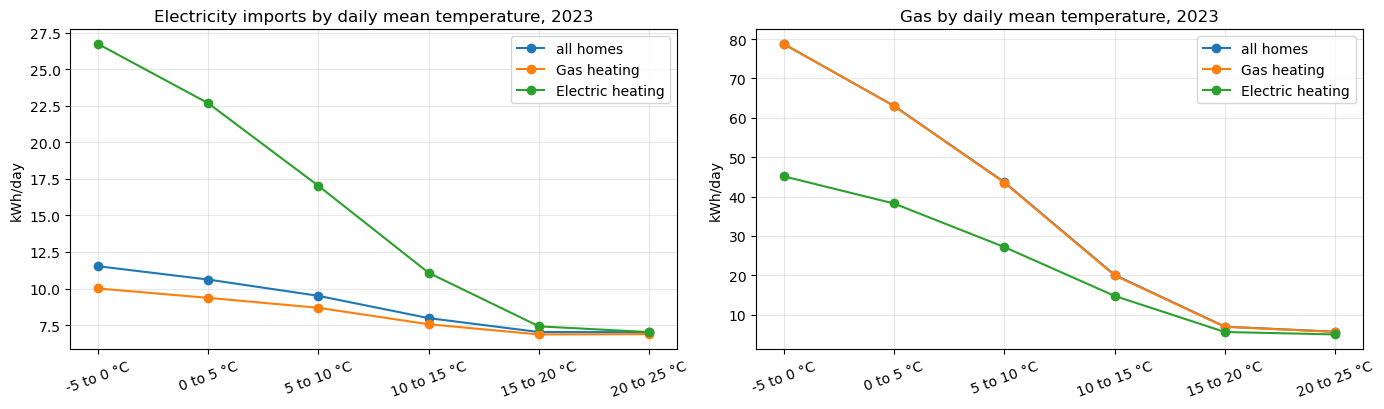

In [6]:
BANDS = ["-5_to_0", "0_to_5", "5_to_10", "10_to_15", "15_to_20", "20_to_25"]
rows = []
for q in ["Electricity imports", "Gas"]:
    for fuel in ("All", "Gas", "Electric"):
        s = su.select_slice(y23, q, "kWh/day", fuel=fuel, segment="temperature_band").set_index("segment_3_value")
        s = s.reindex(BANDS)
        rows += [{"quantity": q, "heating fuel": fuel, "band": b, "kWh/day": v, "households": n}
                 for b, v, n in zip(BANDS, s["mean"], s["n_rounded"])]
temp = pd.DataFrame(rows)
print(temp.pivot_table(index=["quantity", "heating fuel"], columns="band", values="kWh/day", sort=False).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, q in zip(axes, ["Electricity imports", "Gas"]):
    for fuel in ("All", "Gas", "Electric"):
        t = temp[temp["quantity"].eq(q) & temp["heating fuel"].eq(fuel)]
        ax.plot(range(len(BANDS)), t["kWh/day"], marker="o", label=f"{fuel} heating" if fuel != "All" else "all homes")
    ax.set_xticks(range(len(BANDS)), [b.replace("_to_", " to ") + " °C" for b in BANDS], rotation=20)
    ax.set_title(f"{q} by daily mean temperature, 2023"); ax.set_ylabel("kWh/day"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
temp.to_csv("outputs/repro/temperature_response_2023.csv", index=False)

## 6. Solar irradiance and PV exports

Monthly mean exports of PV homes against monthly mean solar irradiance (2020–2023, 48 months).


PV homes, 48 months: Spearman r(solar, exports) = 0.88; r(solar, imports) = -0.87


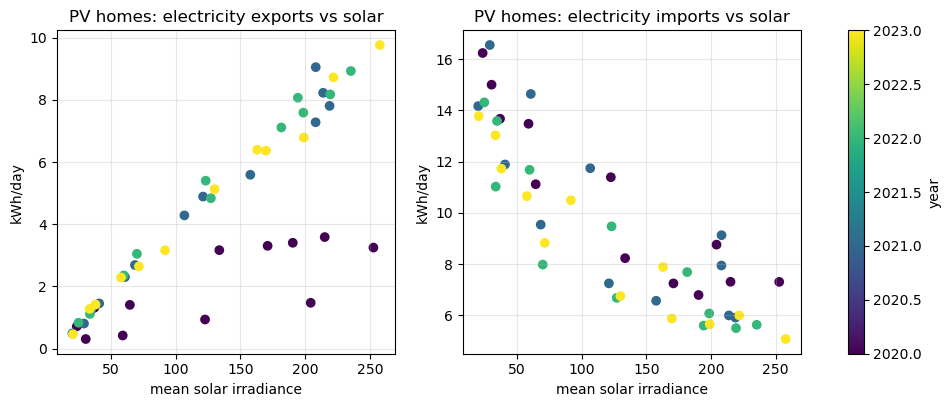

In [7]:
from scipy.stats import spearmanr

pv = su.select_slice(monthly, "Electricity exports", "kWh/day", pv="Yes")
imp = su.select_slice(monthly, "Electricity imports", "kWh/day", pv="Yes")
rho_e, _ = spearmanr(pv["mean_solar"], pv["mean"])
rho_i, _ = spearmanr(imp["mean_solar"], imp["mean"])
print(f"PV homes, 48 months: Spearman r(solar, exports) = {rho_e:.2f}; r(solar, imports) = {rho_i:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, s, title in ((axes[0], pv, "exports"), (axes[1], imp, "imports")):
    sc = ax.scatter(s["mean_solar"], s["mean"], c=s["date"].dt.year, cmap="viridis")
    ax.set_xlabel("mean solar irradiance"); ax.set_ylabel("kWh/day"); ax.set_title(f"PV homes: electricity {title} vs solar")
    ax.grid(alpha=0.3)
fig.colorbar(sc, ax=axes, label="year")
plt.show()